<a href="https://colab.research.google.com/github/AyaAlharthi/diamond-price-prediction/blob/main/Diamonds_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd, numpy as np, seaborn as sns, matplotlib.pyplot as plt
df = sns.load_dataset("diamonds")
print(df.shape)
df.head()

(53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


Missing: 0 | Duplicates: 146


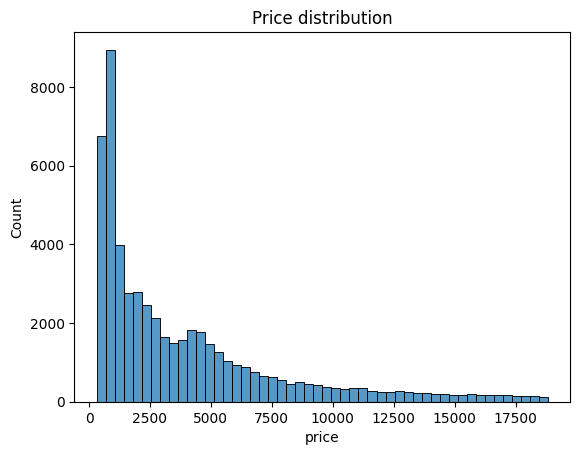

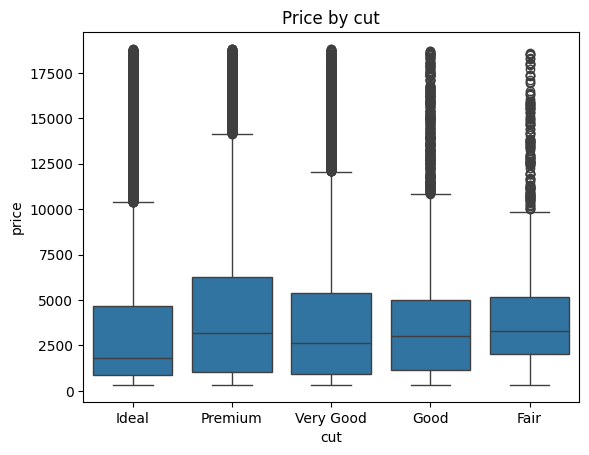

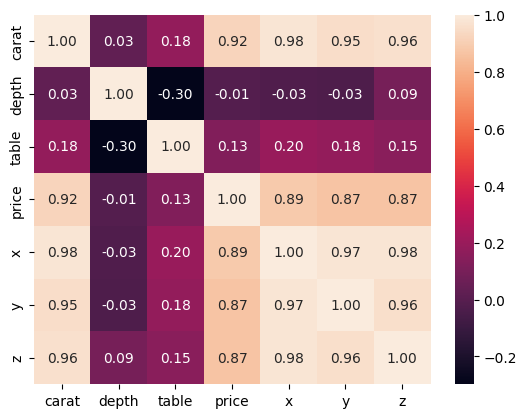

In [2]:
print("Missing:", df.isna().sum().sum(), "| Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()
df = df[(df[["x", "y", "z"]] > 0).all(axis=1)]  # remove invalid dimensions

sns.histplot(df["price"], bins=50); plt.title("Price distribution"); plt.show()
sns.boxplot(data=df, x="cut", y="price"); plt.title("Price by cut"); plt.show()
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f"); plt.show()

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

X = pd.get_dummies(df.drop(columns="price"), drop_first=True)
y = df["price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {"Linear Regression": LinearRegression(),
          "Random Forest": RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)}
for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    print(f"{name}: RMSE={rmse:.0f}, R2={r2_score(y_test, pred):.3f}")

Linear Regression: RMSE=1129, R2=0.919
Random Forest: RMSE=538, R2=0.982


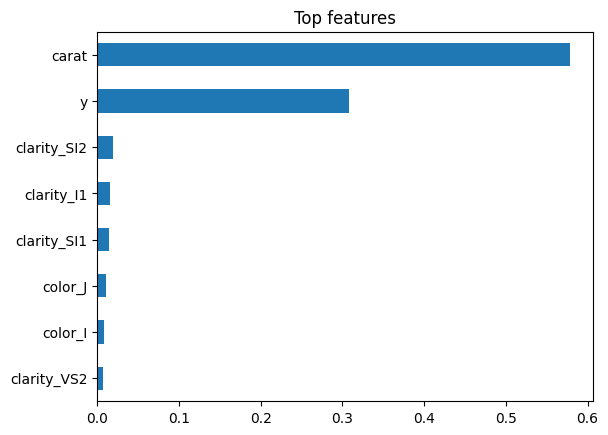

In [4]:
rf = models["Random Forest"]
pd.Series(rf.feature_importances_, index=X.columns).sort_values().tail(8).plot(kind="barh", title="Top features")
plt.show()